# Eccentric MCMC: controlled prior experiment

This notebook reads the new reproducible run rather than silently reusing undocumented legacy arrays. The full model lives in `src/analysis.py`; see `docs/PROJECT_STATUS.md` for priors, selection assumptions, and limitations. Original notebooks 01–03 and 06 remain unchanged.

Sampled eccentric coordinates are $h=\sqrt e\cos\omega$, $k=\sqrt e\sin\omega$. Their constant Jacobian yields uniform $de\,d\omega$ over the disk before applying the low-e exponential weight. The model uses $\cos i=(b/(a/R_*))(1+e\sin\omega)/(1-e^2)$.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/"src/analysis.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT/"src"))
import analysis
RESULTS = ROOT / "results/refined_20261104"

In [2]:
for kind in ["circular", "lowe", "uniform"]:
    diag=json.loads((RESULTS/f"{kind}_diagnostics.json").read_text())
    print(kind, json.dumps(diag,indent=2))

circular {
  "tau": [
    467.0125918796005,
    379.43953494573145,
    377.1481027411229,
    103.00873999031882,
    109.98388163521639,
    105.5853159163223,
    106.11622099827828
  ],
  "approx_ess": [
    3083.4286377683866,
    3795.071065027404,
    3818.1287126570173,
    13979.39631273363,
    13092.827590646863,
    13638.260088564002,
    13570.02714998081
  ],
  "split_rhat_descriptive": [
    1.017531670440011,
    1.0142737101835335,
    1.0146115745047324,
    1.0032684161161678,
    1.0029755169329289,
    1.0029514019079393,
    1.0039236122050854
  ],
  "retained_steps": 30000,
  "acceptance_mean": 0.29928125,
  "convergence_screen_passed": true,
  "warning": "Ensemble walkers interact; this Rhat is not an independent-chain convergence proof. Run independent ensembles and longer chains for final inference.",
  "seed": 137010,
  "steps": 60000,
  "walkers": 48,
  "seconds_continuation": 279.04807233810425,
  "sigma_flux": 3.26435036872614e-05,
  "pmax": 2000,
  "acc

## Inspect traces before interpreting posteriors

The retained chains must be long compared with their autocorrelation time. Split Rhat across interacting walkers is descriptive, not independent-chain validation. A failed screen means exploratory output. For final inference repeat with dispersed initial ensembles and compare stable tail quantiles.

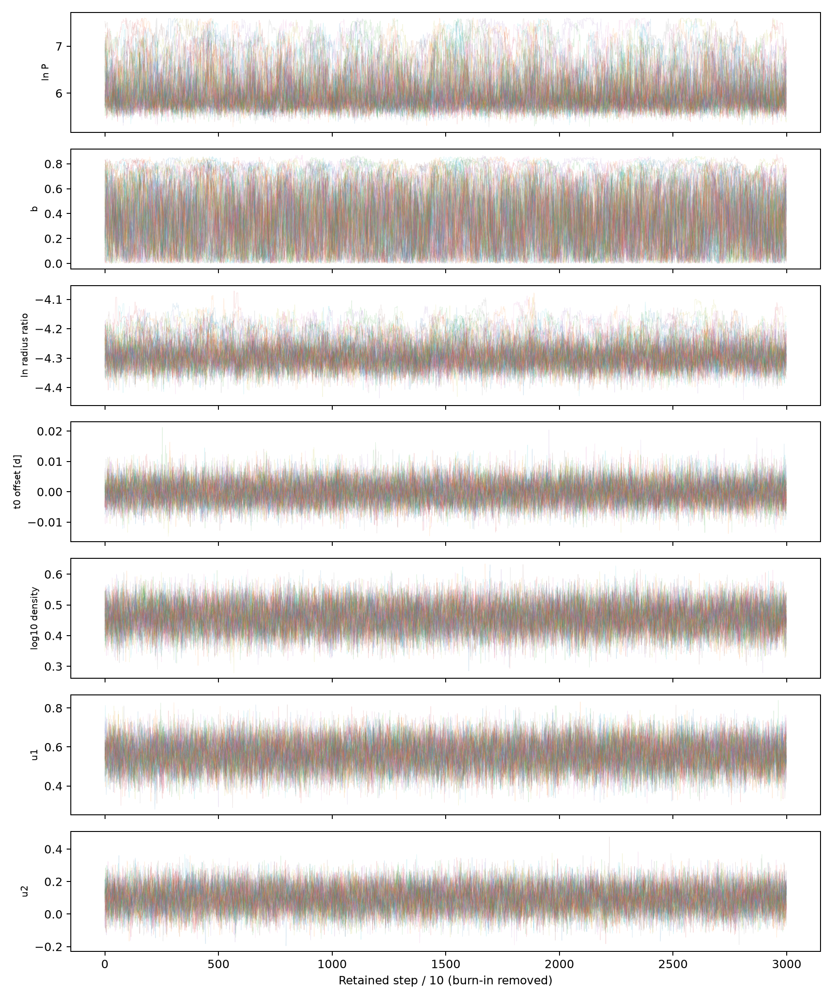

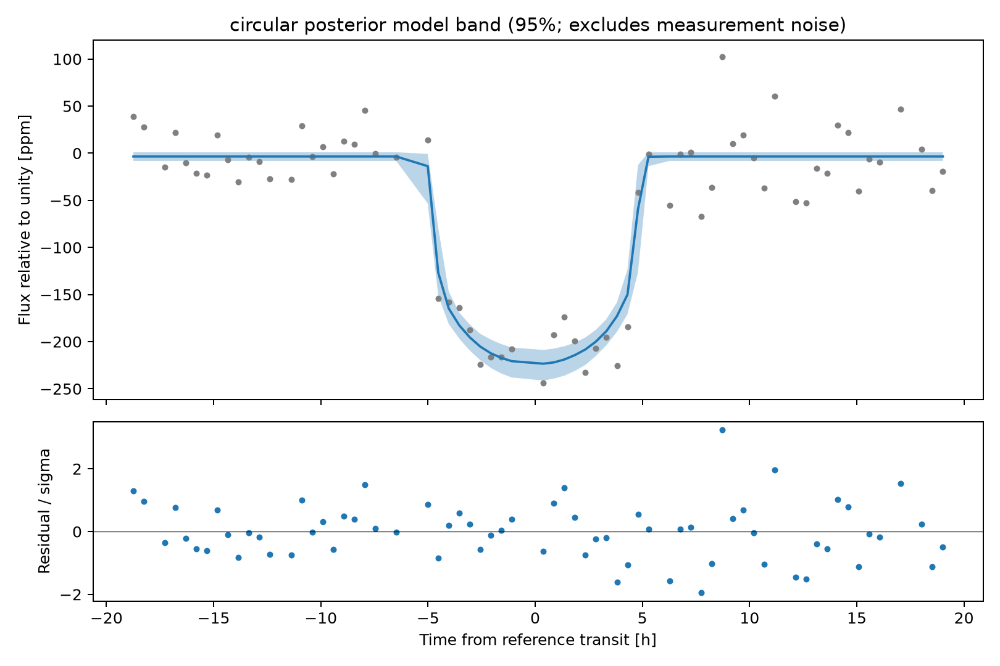

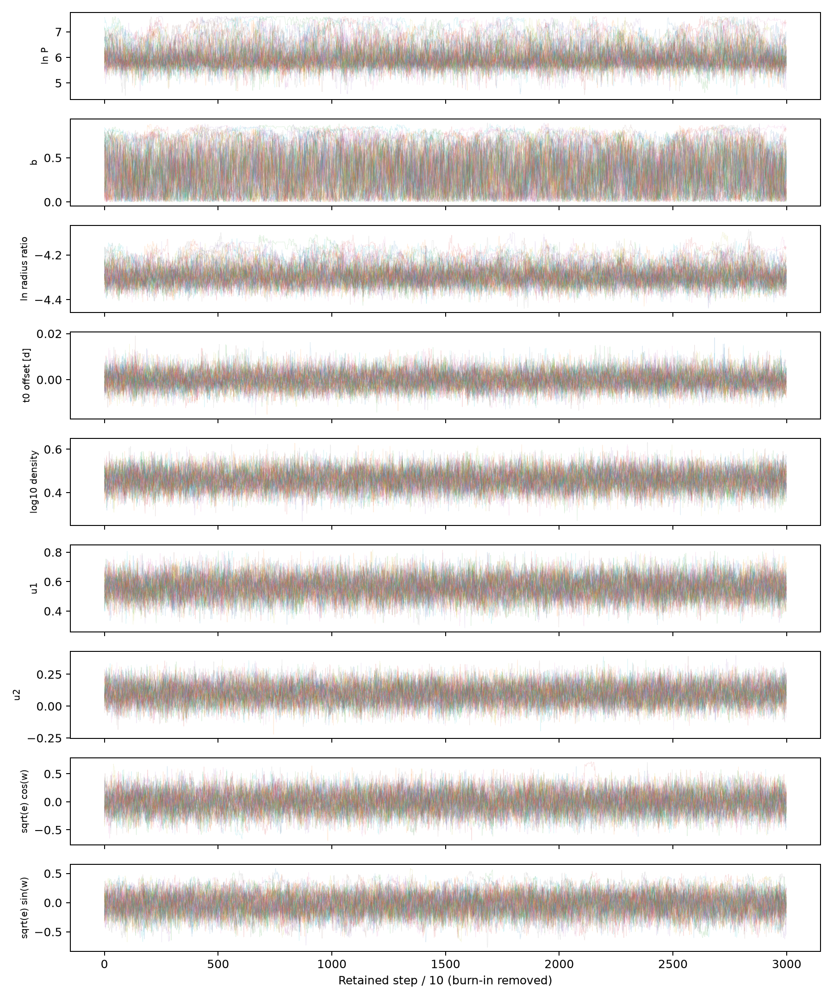

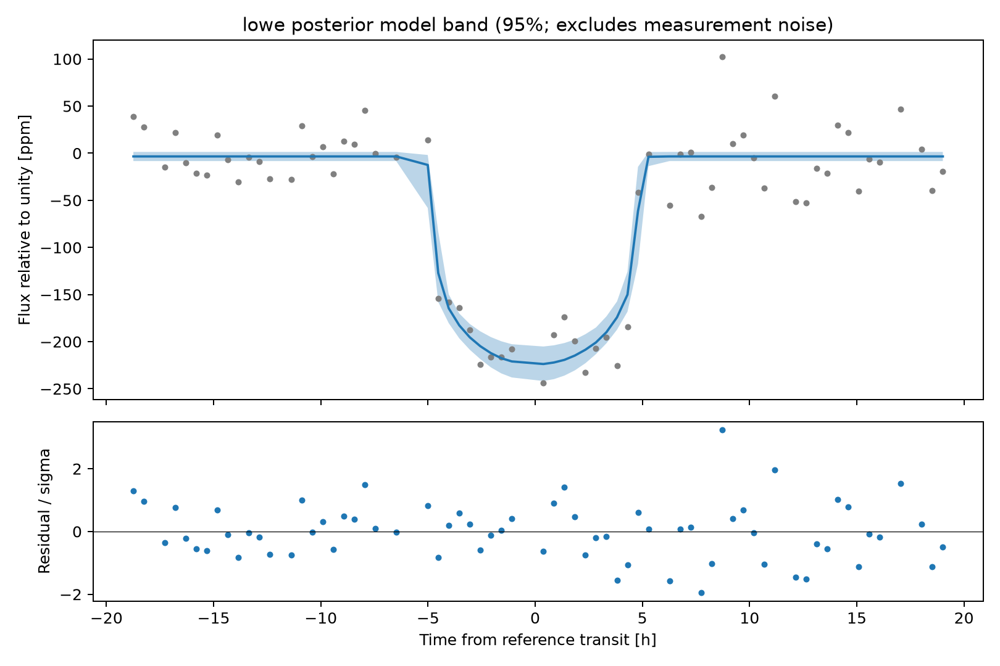

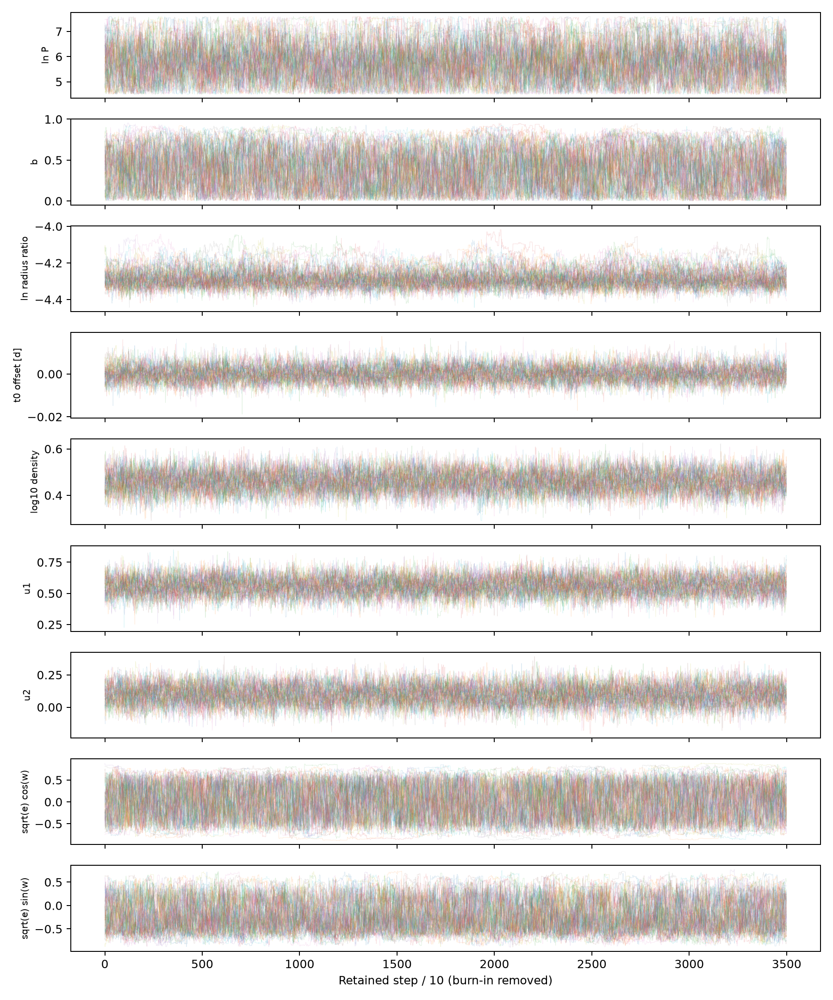

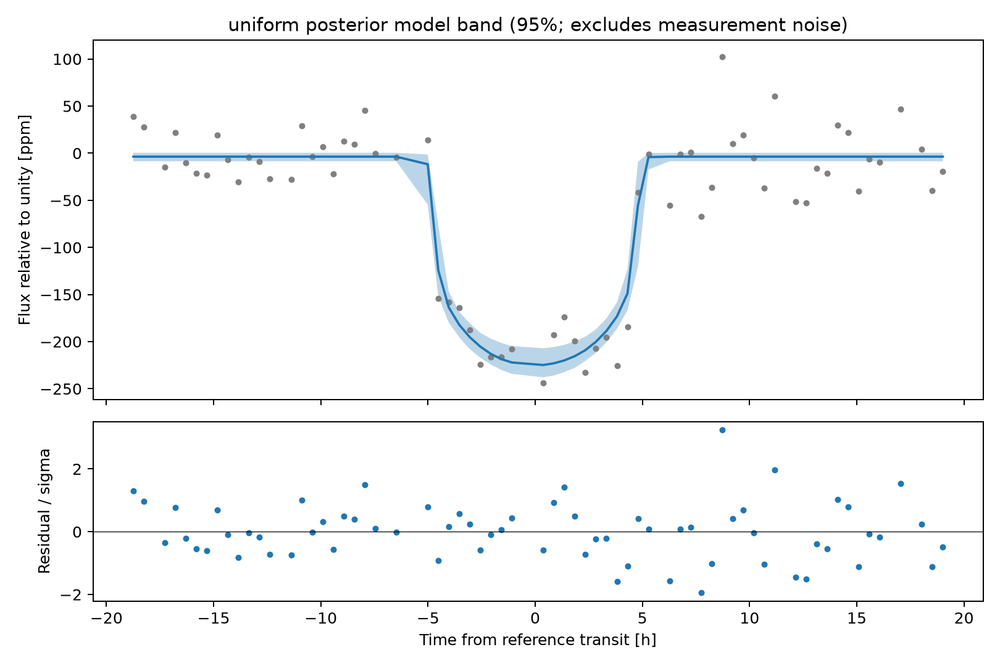

In [3]:
from IPython.display import display, Image
for kind in ["circular", "lowe", "uniform"]:
    display(Image(filename=str(RESULTS/f"{kind}_traces.png")))
    display(Image(filename=str(RESULTS/f"{kind}_model_check.png")))

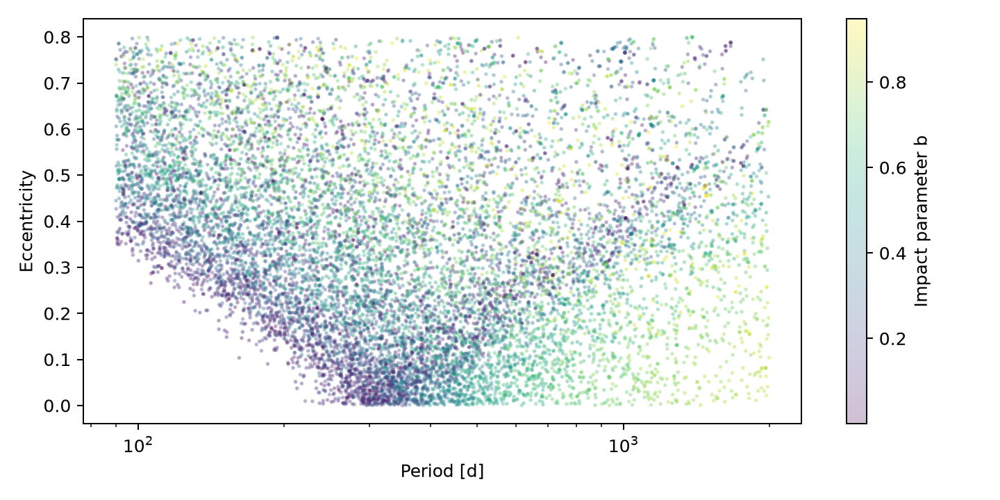

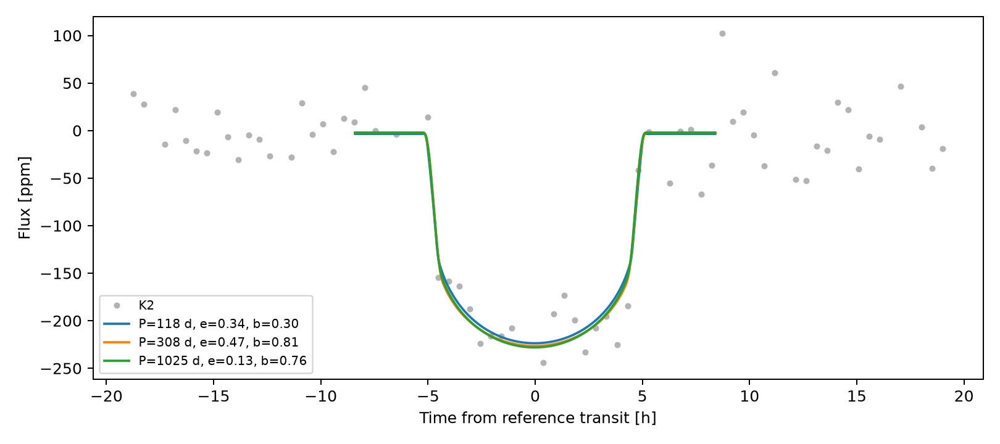

In [4]:
display(Image(filename=str(RESULTS/"period_eccentricity.png")))
display(Image(filename=str(RESULTS/"representative_transits.png")))

## Run a new experiment

From the repository root use `.venv\Scripts\python.exe src\analysis.py --steps 100000 --seed 137020 --output results\independent_run`. A new output directory is required. The script saves complete chains, seeds and input hashes. Keep period support fixed across the three eccentricity comparisons, then test alternative support separately. Do not present a short run as converged simply because its median resembles the paper.